# Ames Housing Price Prediction

## 1. Problem Definition

### Objective
Develop a machine learning regression model that predicts residential house sale prices using property characteristics from the Ames Housing dataset.

### Target Variable
`SalePrice` — the final sale price of a house.

### Project Goals
- Understand the dataset and assess its quality.
- Explore important patterns and relationships in house prices.
- Build a leakage-safe preprocessing and modeling workflow.
- Compare regression models using consistent evaluation metrics.
- Select a model based on validation and cross-validation performance.
- Package the final workflow for reproducible training and future deployment.

### Evaluation Metrics
- **RMSE:** Primary metric; penalizes large prediction errors.
- **MAE:** Measures average absolute prediction error.
- **R²:** Measures predictive performance relative to a mean-prediction baseline.

In [12]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "AmesHousing.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [7]:
print("Dataset dimensions:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing target values:", df["SalePrice"].isna().sum())
print("------------------------------------------------------------------")
display(df.info())

Dataset dimensions: (2930, 82)
Duplicate rows: 0
Missing target values: 0
------------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 

None

## 3. Data Quality Assessment

We will investigate:

- Missing values and their distribution.
- Duplicate records.
- Data types and potentially inconsistent columns.
- Identifier columns that may not provide useful predictive information.
- Whether missing values represent actual data problems or meaningful property characteristics.

**Important:** All cleaning and preprocessing decisions will be documented before implementation. We will preserve the original raw dataset and avoid making transformations at this stage.

In [8]:
# Calculate missing-value statistics
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percentage", ascending=False)
)

display(missing_summary.round(2))

,missing_count,missing_percentage
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Qual,159,5.43
Garage Cond,159,5.43
Garage Yr Blt,159,5.43


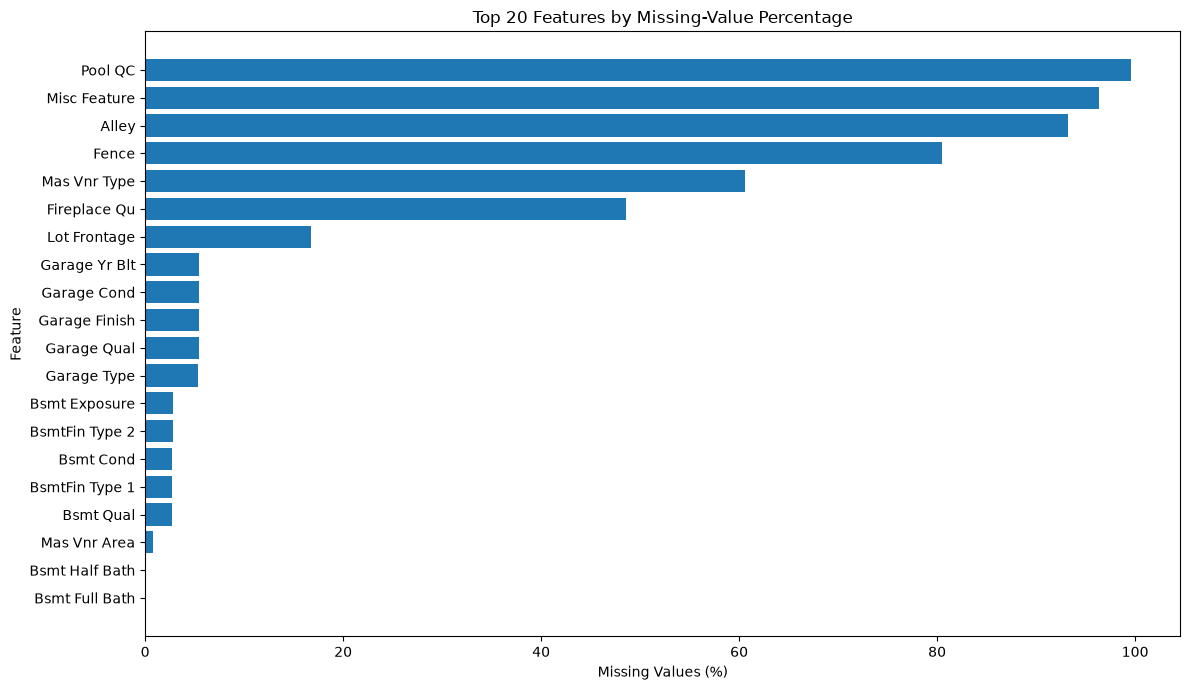

In [9]:
plt.figure(figsize=(12, 7))

missing_to_plot = missing_summary.head(20).sort_values(
    "missing_percentage",
    ascending=True
)

plt.barh(
    missing_to_plot.index,
    missing_to_plot["missing_percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Top 20 Features by Missing-Value Percentage")
plt.tight_layout()
plt.show()

In [10]:
duplicate_count = df.duplicated().sum()

print(f"Number of fully duplicated rows: {duplicate_count}")
print(f"Percentage of duplicated rows: {duplicate_count / len(df) * 100:.2f}%")

Number of fully duplicated rows: 0
Percentage of duplicated rows: 0.00%


In [17]:
# That help you to identify numeric columns, categorical columns, and define the potential data quality issues
data_profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=True),
    "missing_count": df.isna().sum()
})

data_profile.T

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
dtype,int64,int64,int64,str,float64,int64,str,str,str,str,str,str,str,str,str,str,str,str,int64,int64,int64,int64,str,str,str,str,str,float64,str,str,str,str,str,str,str,float64,str,float64,float64,float64,str,str,str,str,int64,int64,int64,int64,float64,float64,int64,int64,int64,int64,str,int64,str,int64,str,str,float64,str,float64,float64,str,str,str,int64,int64,int64,int64,int64,int64,str,str,str,int64,int64,int64,str,str,int64
unique_values,2930,2930,16,7,128,1960,2,2,4,4,3,5,3,28,9,8,5,8,10,9,118,61,6,8,16,17,4,445,4,5,6,5,5,4,6,995,6,274,1137,1058,6,5,2,5,1083,635,36,1292,4,3,5,3,8,4,5,14,8,5,5,6,103,3,6,603,5,5,3,380,252,183,31,121,14,4,4,5,38,12,5,10,6,1032
missing_count,0,0,0,0,490,0,0,2732,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1775,23,0,0,0,80,80,83,80,1,81,1,1,1,0,0,0,1,0,0,0,0,2,2,0,0,0,0,0,0,0,0,1422,157,159,159,1,1,159,159,0,0,0,0,0,0,0,2917,2358,2824,0,0,0,0,0,0


In [18]:
# Inspect columns whose names suggest identifiers
identifier_candidates = [
    col for col in df.columns
    if any(term in col.lower() for term in ["id", "pid", "order"])
]

for col in identifier_candidates:
    print(f"\n{col}")
    print(f"Unique values: {df[col].nunique(dropna=True)}")
    print(f"Missing values: {df[col].isna().sum()}")
    display(df[col].head())


Order
Unique values: 2930
Missing values: 0


0    1
1    2
2    3
3    4
4    5
Name: Order, dtype: int64


PID
Unique values: 2930
Missing values: 0


0    526301100
1    526350040
2    526351010
3    526353030
4    527105010
Name: PID, dtype: int64

### 3.1 Investigating Missing-Value Meaning

Missing values may indicate either genuinely unknown information or the absence of a property feature. We will compare selected missing-value columns with related features to distinguish these cases before deciding how to impute them.

In [19]:
# Investigate missing values alongside related property features

checks = {
    "Pool QC": ["Pool Area"],
    "Fireplace Qu": ["Fireplaces"],
    "Garage Type": ["Garage Cars", "Garage Area"],
    "Mas Vnr Type": ["Mas Vnr Area"],
    "Bsmt Qual": ["Total Bsmt SF"],
}

for missing_col, related_cols in checks.items():
    print(f"\n{'=' * 60}")
    print(f"Missing column: {missing_col}")
    print(f"Missing values: {df[missing_col].isna().sum()}")

    for related_col in related_cols:
        print(f"\nRelated feature: {related_col}")
        display(
            df.loc[
                df[missing_col].isna(),
                related_col
            ].value_counts(dropna=False).head(10)
        )


Missing column: Pool QC
Missing values: 2917

Related feature: Pool Area


Pool Area
0    2917
Name: count, dtype: int64


Missing column: Fireplace Qu
Missing values: 1422

Related feature: Fireplaces


Fireplaces
0    1422
Name: count, dtype: int64


Missing column: Garage Type
Missing values: 157

Related feature: Garage Cars


Garage Cars
0.0    157
Name: count, dtype: int64

... (2 outputs left out)


Missing column: Mas Vnr Type
Missing values: 1775

Related feature: Mas Vnr Area


Mas Vnr Area
0.0      1745
NaN        23
1.0         3
344.0       1
312.0       1
285.0       1
288.0       1
Name: count, dtype: int64


Missing column: Bsmt Qual
Missing values: 80

Related feature: Total Bsmt SF


Total Bsmt SF
0.0    79
NaN     1
Name: count, dtype: int64

In [23]:
# Find properties with missing veneer type but positive veneer area
veneer_exceptions = df.loc[
    df["Mas Vnr Type"].isna()
    & df["Mas Vnr Area"].gt(0),
    ["PID", "Mas Vnr Type", "Mas Vnr Area", "SalePrice",
     "Overall Qual", "Exterior 1st", "Exterior 2nd"]
]

display(veneer_exceptions)

,PID,Mas Vnr Type,Mas Vnr Area,SalePrice,Overall Qual,Exterior 1st,Exterior 2nd
363,527166010,NaN,344.0,225000,7,VinylSd,VinylSd
403,527451110,NaN,312.0,125000,5,HdBoard,HdBoard
441,528138010,NaN,285.0,324000,9,VinylSd,VinylSd
1861,533352075,NaN,1.0,190000,5,Plywood,Plywood
1913,535106140,NaN,1.0,114500,5,Wd Sdng,Wd Sdng
2003,902427140,NaN,1.0,104500,4,MetalSd,MetalSd
2528,534129230,NaN,288.0,165150,6,VinylSd,VinylSd


In [21]:
veneer_both_missing = df.loc[
    df["Mas Vnr Type"].isna()
    & df["Mas Vnr Area"].isna(),
    ["PID", "Mas Vnr Type", "Mas Vnr Area", "SalePrice"]
]

display(veneer_both_missing)

,PID,Mas Vnr Type,Mas Vnr Area,SalePrice
55,528240070,NaN,NaN,216500
484,528275160,NaN,NaN,257500
517,528458020,NaN,NaN,225000
538,531371050,NaN,NaN,184900
867,907260030,NaN,NaN,198500
1095,528290090,NaN,NaN,176000
1119,528439010,NaN,NaN,247000
1122,528462040,NaN,NaN,182000
1127,528480160,NaN,NaN,205950
1184,534104100,NaN,NaN,205000


In [24]:
# Verify the veneer exceptions
print("Missing veneer type, positive veneer area:")
print(
    (
        df["Mas Vnr Type"].isna()
        & df["Mas Vnr Area"].gt(0)
    ).sum()
)

print("\nMissing veneer type AND missing veneer area:")
print(
    (
        df["Mas Vnr Type"].isna()
        & df["Mas Vnr Area"].isna()
    ).sum()
)

print("\nMissing veneer type AND zero veneer area:")
print(
    (
        df["Mas Vnr Type"].isna()
        & df["Mas Vnr Area"].eq(0)
    ).sum()
)

Missing veneer type, positive veneer area:
7

Missing veneer type AND missing veneer area:
23

Missing veneer type AND zero veneer area:
1745


### 3.2 Initial Data Quality Findings

The dataset contains 2,930 records and 82 columns, with no fully duplicated rows and no missing target values.

Several missing-value patterns appear structural rather than accidental:

- Missing `Pool QC` values coincide with zero pool area.
- Missing `Fireplace Qu` values coincide with zero fireplaces.
- Missing garage types coincide with zero garage capacity and area.
- Most missing `Mas Vnr Type` values coincide with zero veneer area.
- Most missing `Bsmt Qual` values coincide with zero basement area.

These findings suggest that missing categorical values frequently indicate absent property features. However, exceptions and remaining columns require investigation before defining final preprocessing rules.

`Order` and `PID` are unique identifiers and will be evaluated for exclusion from the predictor features.


### 3.3 Missing-Value Investigation: Masonry Veneer

The investigation identified three distinct patterns:

- **1,745 records:** `Mas Vnr Type` is missing while `Mas Vnr Area` equals zero. These records likely represent properties without masonry veneer.
- **7 records:** `Mas Vnr Type` is missing while `Mas Vnr Area` is positive. These records contain incomplete or inconsistent veneer information.
- **23 records:** Both `Mas Vnr Type` and `Mas Vnr Area` are missing. The actual veneer status cannot be established from these two features alone.



## 4. Exploratory Data Analysis (EDA)


The objectives are to:

- Understand the distribution and variability of the target variable, `SalePrice`.
- Identify potential outliers and unusual observations.
- Explore relationships between property characteristics and sale prices.
- Identify patterns that may inform feature engineering and model selection.


In [25]:
target = df["SalePrice"]

print("SalePrice Summary Statistics")
display(target.describe())

print(f"Skewness: {target.skew():.3f}")
print(f"Kurtosis: {target.kurtosis():.3f}")

SalePrice Summary Statistics


count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness: 1.744
Kurtosis: 5.119


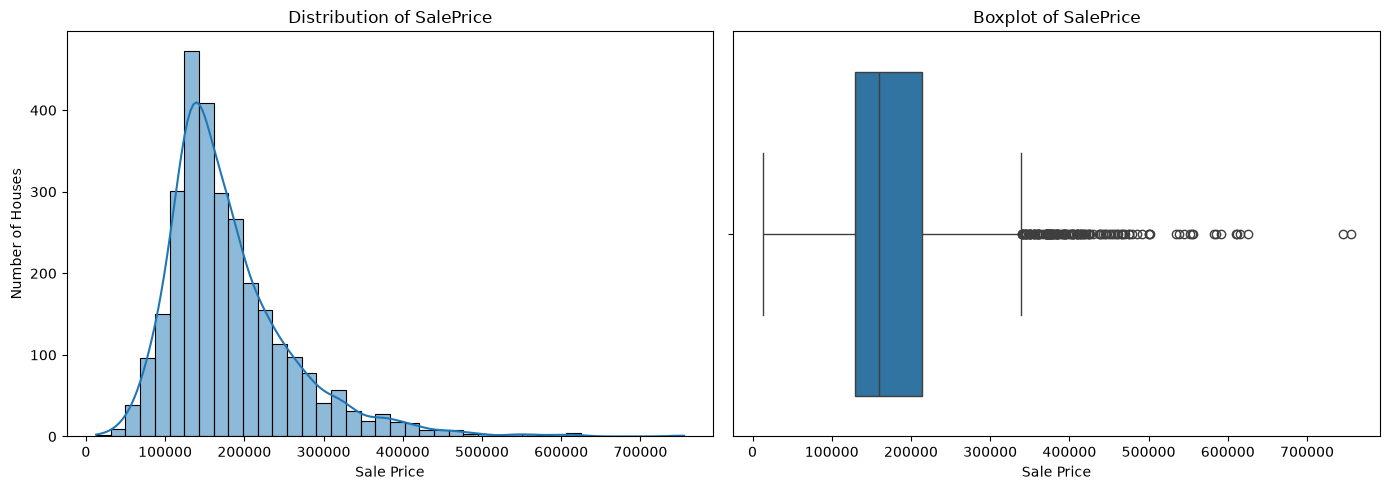

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="SalePrice",
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("Sale Price")
axes[0].set_ylabel("Number of Houses")

sns.boxplot(
    data=df,
    x="SalePrice",
    ax=axes[1]
)
axes[1].set_title("Boxplot of SalePrice")
axes[1].set_xlabel("Sale Price")

plt.tight_layout()
plt.show()

In [27]:
price_quantiles = df["SalePrice"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(price_quantiles.rename("SalePrice").to_frame())

print("\nTen most expensive properties:")
display(
    df.nlargest(10, "SalePrice")[
        [
            "SalePrice",
            "Overall Qual",
            "Gr Liv Area",
            "Total Bsmt SF",
            "Garage Cars",
            "Year Built"
        ]
    ]
)

,SalePrice
0.01,61756.07
0.05,87500.00
0.25,129500.00
0.50,160000.00
0.75,213500.00
0.90,281241.70
0.95,335000.00
0.99,456666.37



Ten most expensive properties:


,SalePrice,Overall Qual,Gr Liv Area,Total Bsmt SF,Garage Cars,Year Built
1767,755000,10,4316,2444.0,3.0,1994
1760,745000,10,4476,2396.0,3.0,1996
2445,625000,10,3627,1930.0,3.0,1995
1063,615000,10,2470,2535.0,3.0,2003
44,611657,9,2364,2330.0,3.0,2009
432,610000,10,2674,2630.0,3.0,2007
1637,591587,9,2338,2660.0,3.0,2006
2450,584500,9,3500,1733.0,3.0,1993
433,582933,9,2822,1734.0,3.0,2008
2332,556581,9,2868,1992.0,3.0,2005


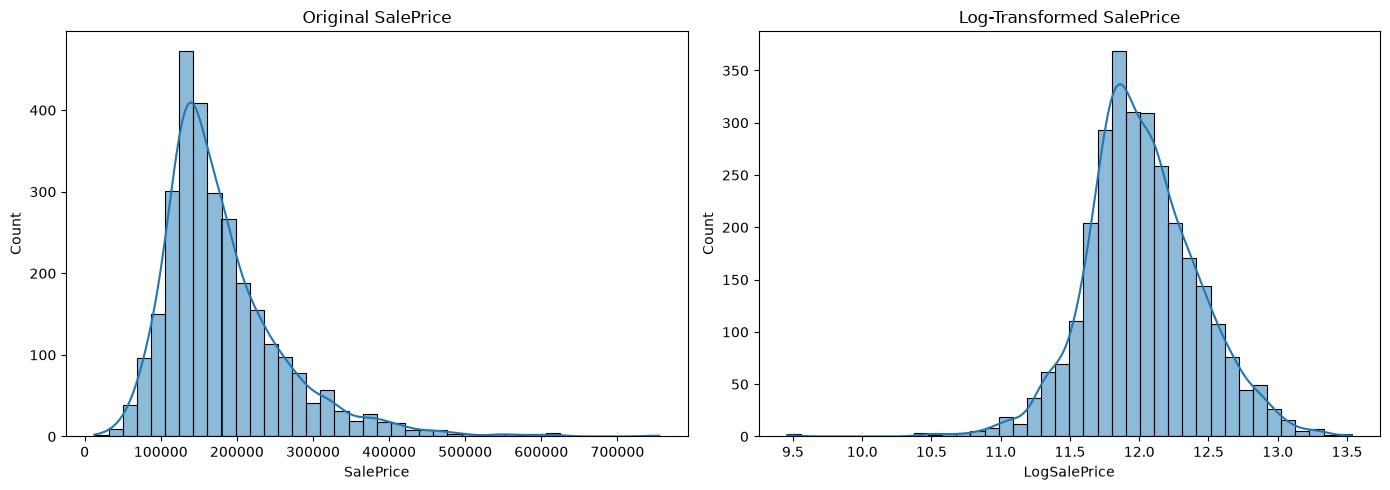

Original skewness: 1.744
Log skewness: -0.015
Log Kurtosis: 1.514


In [30]:
df["LogSalePrice"] = np.log1p(df["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["SalePrice"],
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Original SalePrice")

sns.histplot(
    df["LogSalePrice"],
    bins=40,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Log-Transformed SalePrice")

plt.tight_layout()
plt.show()

print(f"Original skewness: {df['SalePrice'].skew():.3f}")
print(f"Log skewness: {df['LogSalePrice'].skew():.3f}")
print(f'Log Kurtosis: {df['LogSalePrice'].kurtosis():.3f}')

### 4.1 Target Variable Analysis

The target variable, `SalePrice`, has 2,930 observations, a mean of approximately 180,796, a median of 160,000, and a standard deviation of approximately 79,887.

The original target distribution is positively skewed, with skewness of 1.744 and kurtosis of 5.119. The histogram shows a long right tail, and the boxplot identifies numerous high-priced observations as potential outliers.

Inspection of the ten most expensive properties shows that these observations generally have high overall quality ratings and large living areas. They may represent legitimate high-value properties rather than data errors, so they will not be removed solely because they are statistical outliers.

Applying `log1p` to `SalePrice` reduces its skewness to approximately -0.015, producing a substantially more symmetric distribution.

**Modeling implication:** We will consider models trained on both the original and log-transformed target. Their performance will be compared using validation or cross-validation predictions converted to the original price scale. The transformation will be treated as an experimental choice rather than an automatic improvement.

In [31]:
numeric_features = [
    "Overall Qual",
    "Gr Liv Area",
    "Total Bsmt SF",
    "Garage Area",
    "Year Built",
    "Lot Area"
]

display(df[numeric_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
Overall Qual,2930.0,6.094881,1.411026,1.0,5.00,6.0,7.00,10.0
Gr Liv Area,2930.0,1499.690444,505.508887,334.0,1126.00,1442.0,1742.75,5642.0
Total Bsmt SF,2929.0,1051.614544,440.615067,0.0,793.00,990.0,1302.00,6110.0
Garage Area,2929.0,472.819734,215.046549,0.0,320.00,480.0,576.00,1488.0
Year Built,2930.0,1971.356314,30.245361,1872.0,1954.00,1973.0,2001.00,2010.0
Lot Area,2930.0,10147.921843,7880.017759,1300.0,7440.25,9436.5,11555.25,215245.0


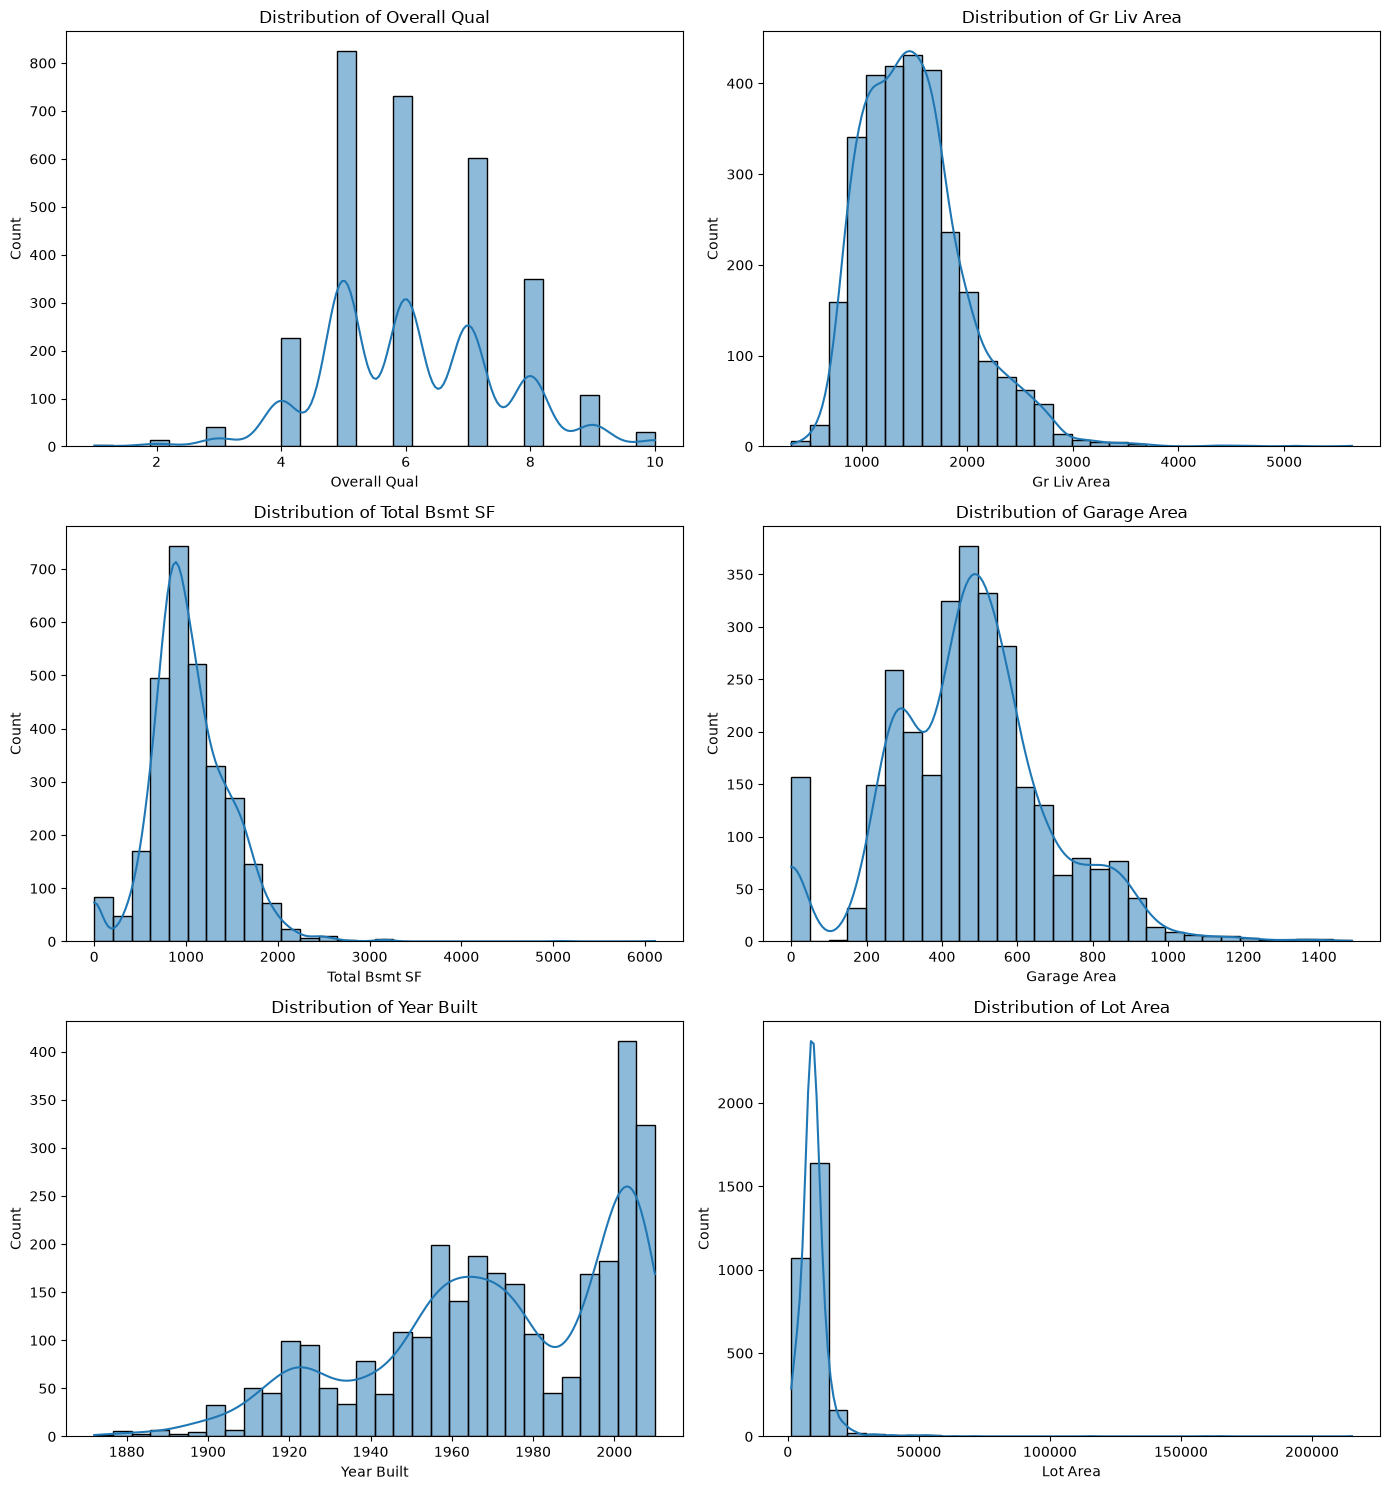

In [32]:
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for feature, ax in zip(numeric_features, axes.flat):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=30,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)

plt.tight_layout()
plt.show()

In [33]:
feature_distribution = pd.DataFrame({
    "skewness": df[numeric_features].skew(),
    "unique_values": df[numeric_features].nunique(),
    "missing_values": df[numeric_features].isna().sum()
})

display(
    feature_distribution.sort_values(
        "skewness",
        ascending=False
    ).round(3)
)

,skewness,unique_values,missing_values
Lot Area,12.821,1960,0
Gr Liv Area,1.274,1292,0
Total Bsmt SF,1.156,1058,1
Garage Area,0.242,603,1
Overall Qual,0.191,10,0
Year Built,-0.604,118,0


In [34]:
area_features = [
    "Gr Liv Area",
    "Total Bsmt SF",
    "Lot Area"
]

for feature in area_features:
    print(f"\nLargest values for {feature}:")
    display(
        df.nlargest(10, feature)[
            ["SalePrice", "Overall Qual", feature, "Year Built"]
        ]
    )


Largest values for Gr Liv Area:


,SalePrice,Overall Qual,Gr Liv Area,Year Built
1498,160000,10,5642,2008
2180,183850,10,5095,2008
2181,184750,10,4676,2007
1760,745000,10,4476,1996
1767,755000,10,4316,1994
1497,284700,5,3820,1959
2737,415000,6,3672,1935
2445,625000,10,3627,1995
2666,475000,10,3608,1892
2450,584500,9,3500,1993



Largest values for Total Bsmt SF:


,SalePrice,Overall Qual,Total Bsmt SF,Year Built
1498,160000,10,6110.0,2008
2180,183850,10,5095.0,2008
444,284000,8,3206.0,2003
1772,430000,8,3200.0,1992
2181,184750,10,3138.0,2007
423,555000,10,3094.0,2008
46,500000,9,2846.0,2003
1637,591587,9,2660.0,2006
1763,466500,10,2633.0,2001
432,610000,10,2630.0,2007



Largest values for Lot Area:


,SalePrice,Overall Qual,Lot Area,Year Built
956,375000,7,215245,1965
1570,228950,5,164660,1965
2115,277000,6,159000,1958
2071,302000,7,115149,1971
2766,280000,7,70761,1975
1498,160000,10,63887,2008
314,160000,5,57200,1948
1610,103000,5,56600,1900
15,538000,8,53504,2003
1402,256000,4,53227,1954


In [35]:
selected_feature_missingness = pd.DataFrame({
    "missing_count": df[numeric_features].isna().sum(),
    "missing_percentage": df[numeric_features].isna().mean() * 100
})

display(
    selected_feature_missingness.sort_values(
        "missing_percentage",
        ascending=False
    ).round(2)
)

,missing_count,missing_percentage
Garage Area,1,0.03
Total Bsmt SF,1,0.03
Gr Liv Area,0,0.00
Overall Qual,0,0.00
Year Built,0,0.00
Lot Area,0,0.00


### 4.2 Univariate Analysis of Features

The numerical feature distributions reveal substantial differences in their shapes.

`Lot Area` is extremely right-skewed (skewness 12.821), while `Gr Liv Area` (1.274) and `Total Bsmt SF` (1.156) are moderately right-skewed. These features contain unusually large values that warrant investigation before deciding whether transformations or special handling are appropriate.

`Garage Area` has relatively low skewness (0.242), although its distribution includes a group of zero-area properties. These zeros may represent houses without garages rather than missing measurements.

`Overall Qual` is an ordinal rating rather than a continuous measurement. `Year Built` is a calendar-year feature whose distribution is concentrated among newer properties.

The largest living-area observations include properties with exceptionally large recorded areas but comparatively low sale prices. These observations will be investigated further rather than automatically removed. The largest lot measurements will also be reviewed to distinguish legitimate large properties from potential data-quality issues.

**Preliminary modeling implications:** Log transformations of strongly skewed features and age-based feature engineering are potential experiments. Their usefulness will be evaluated empirically rather than assumed.

### 4.3 Categorical Feature Analysis

Categorical features describe property characteristics such as neighborhood, zoning, building type, exterior materials, and sale conditions.

This analysis will examine category frequencies, identify rare categories, and explore differences in sale prices across selected categorical features.

The findings will help inform encoding strategies and identify potentially informative predictors. Categorical relationships with sale price are exploratory and do not, by themselves, establish causation.

In [41]:
# As usual I'll start with six features representing different aspects of a property.
categorical_features = [
    "Neighborhood",
    "MS Zoning",
    "Bldg Type",
    "House Style",
    "Exterior 1st",
    "Sale Condition"
]

display(df[categorical_features].describe().T)

,count,unique,top,freq
Neighborhood,2930,28,NAmes,443
MS Zoning,2930,7,RL,2273
Bldg Type,2930,5,1Fam,2425
House Style,2930,8,1Story,1481
Exterior 1st,2930,16,VinylSd,1026
Sale Condition,2930,6,Normal,2413


In [ ]:
# Inspect category frequencies
for feature in categorical_features:
    print(f"\n{'=' * 60}")
    print(f"{feature}:")
    display(
        df[feature]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )


Neighborhood:


,Category,Count
0,NAmes,443
1,CollgCr,267
2,OldTown,239
3,Edwards,194
4,Somerst,182
5,NridgHt,166
6,Gilbert,165
7,Sawyer,151
8,NWAmes,131
9,SawyerW,125



MS Zoning:


,Category,Count
0,RL,2273
1,RM,462
2,FV,139
3,RH,27
4,C (all),25
5,I (all),2
6,A (agr),2



Bldg Type:


,Category,Count
0,1Fam,2425
1,TwnhsE,233
2,Duplex,109
3,Twnhs,101
4,2fmCon,62


... (2 outputs left out)


Exterior 1st:


,Category,Count
0,VinylSd,1026
1,MetalSd,450
2,HdBoard,442
3,Wd Sdng,420
4,Plywood,221
5,CemntBd,126
6,BrkFace,88
7,WdShing,56
8,AsbShng,44
9,Stucco,43



Sale Condition:


,Category,Count
0,Normal,2413
1,Partial,245
2,Abnorml,190
3,Family,46
4,Alloca,24
5,AdjLand,12


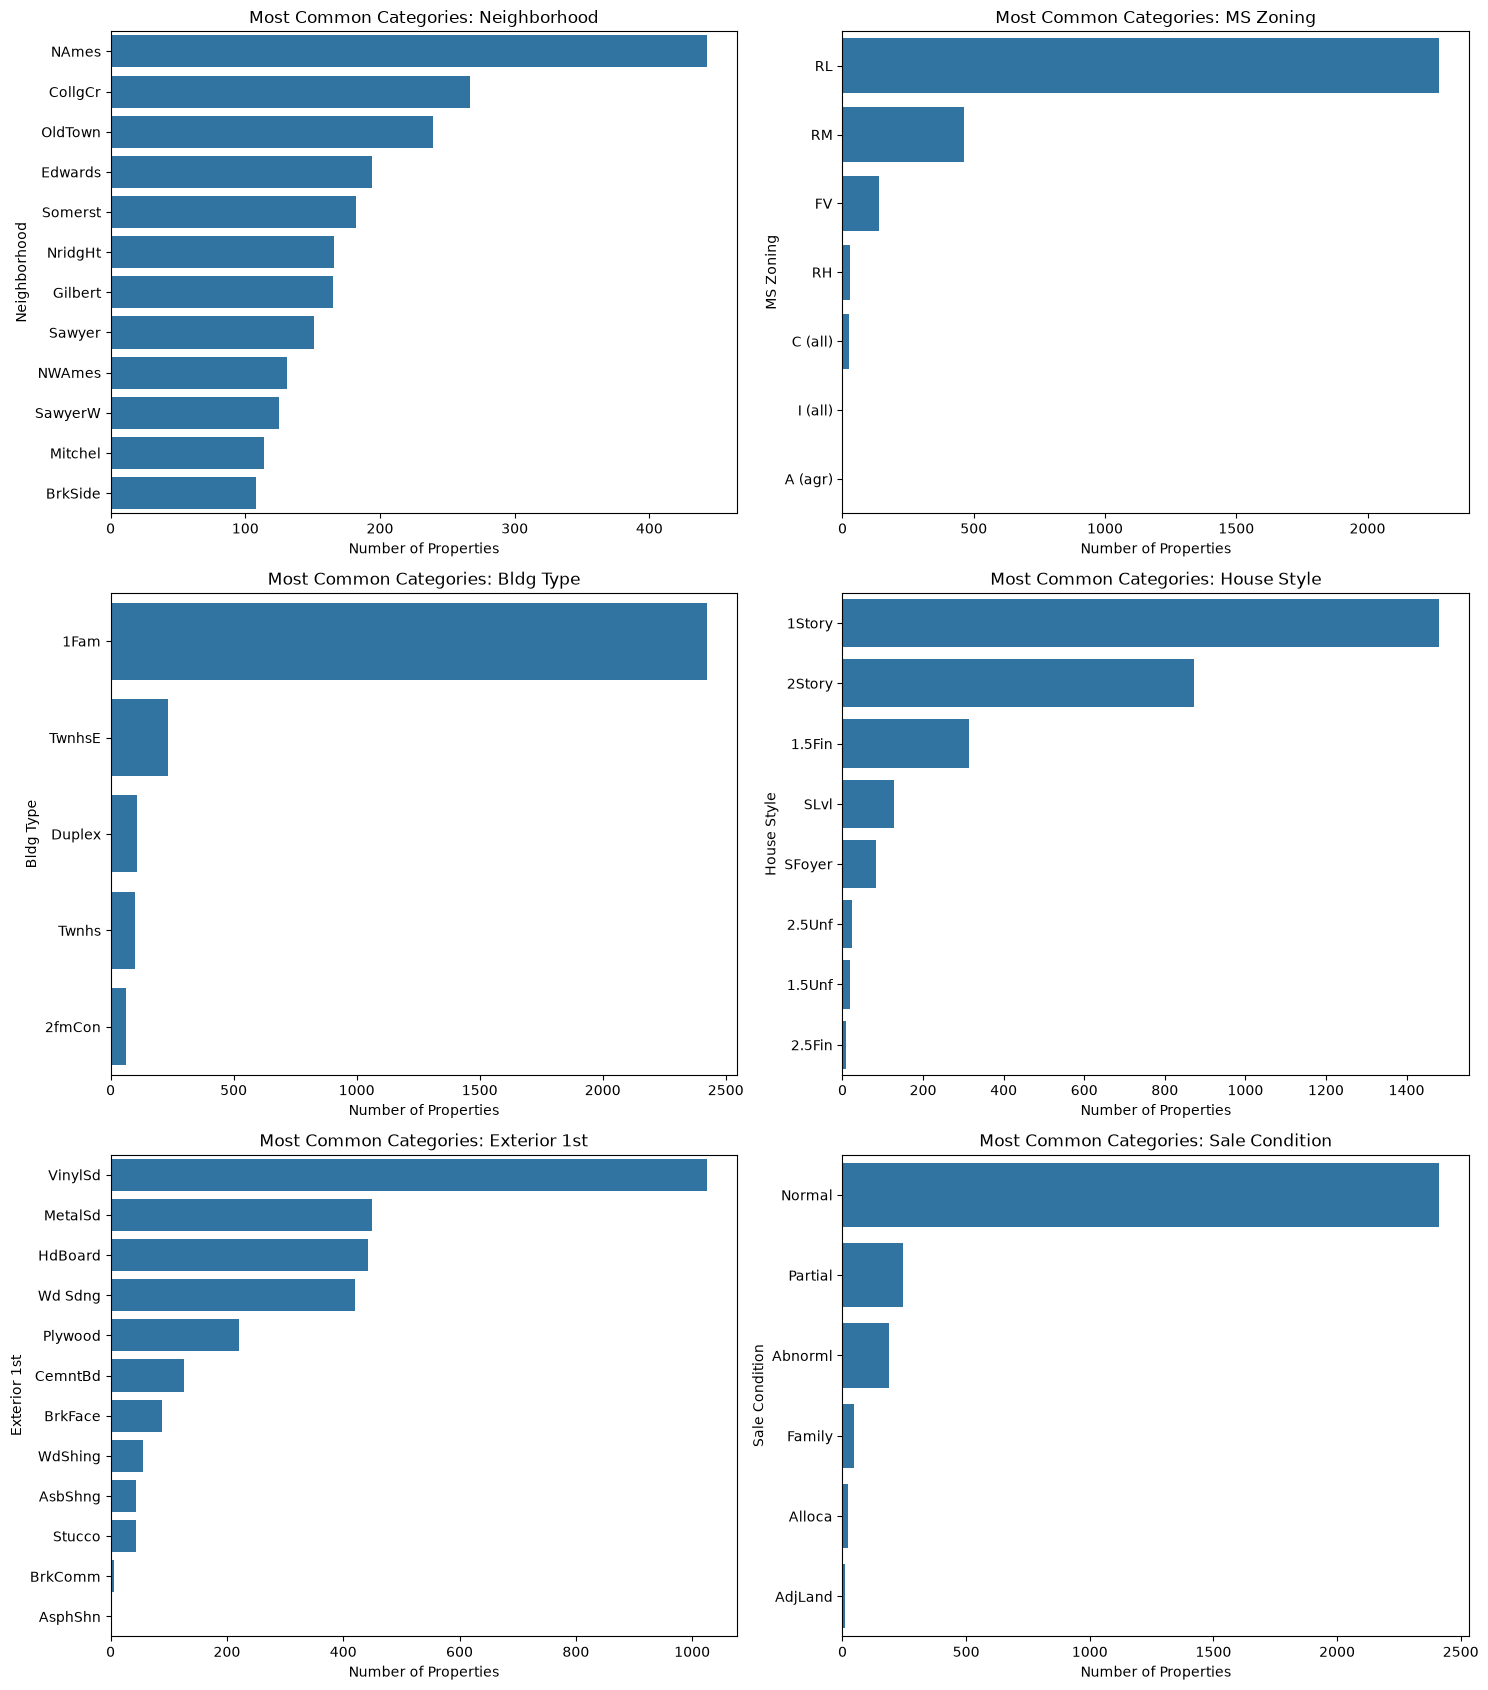

In [ ]:
# Visualize category frequencies

fig, axes = plt.subplots(3, 2, figsize=(15, 17))

for feature, ax in zip(categorical_features, axes.flat):
    counts = df[feature].value_counts().head(12)

    sns.barplot(
        x=counts.values,
        y=counts.index,
        ax=ax
    )

    ax.set_title(f"Most Common Categories: {feature}")
    ax.set_xlabel("Number of Properties")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

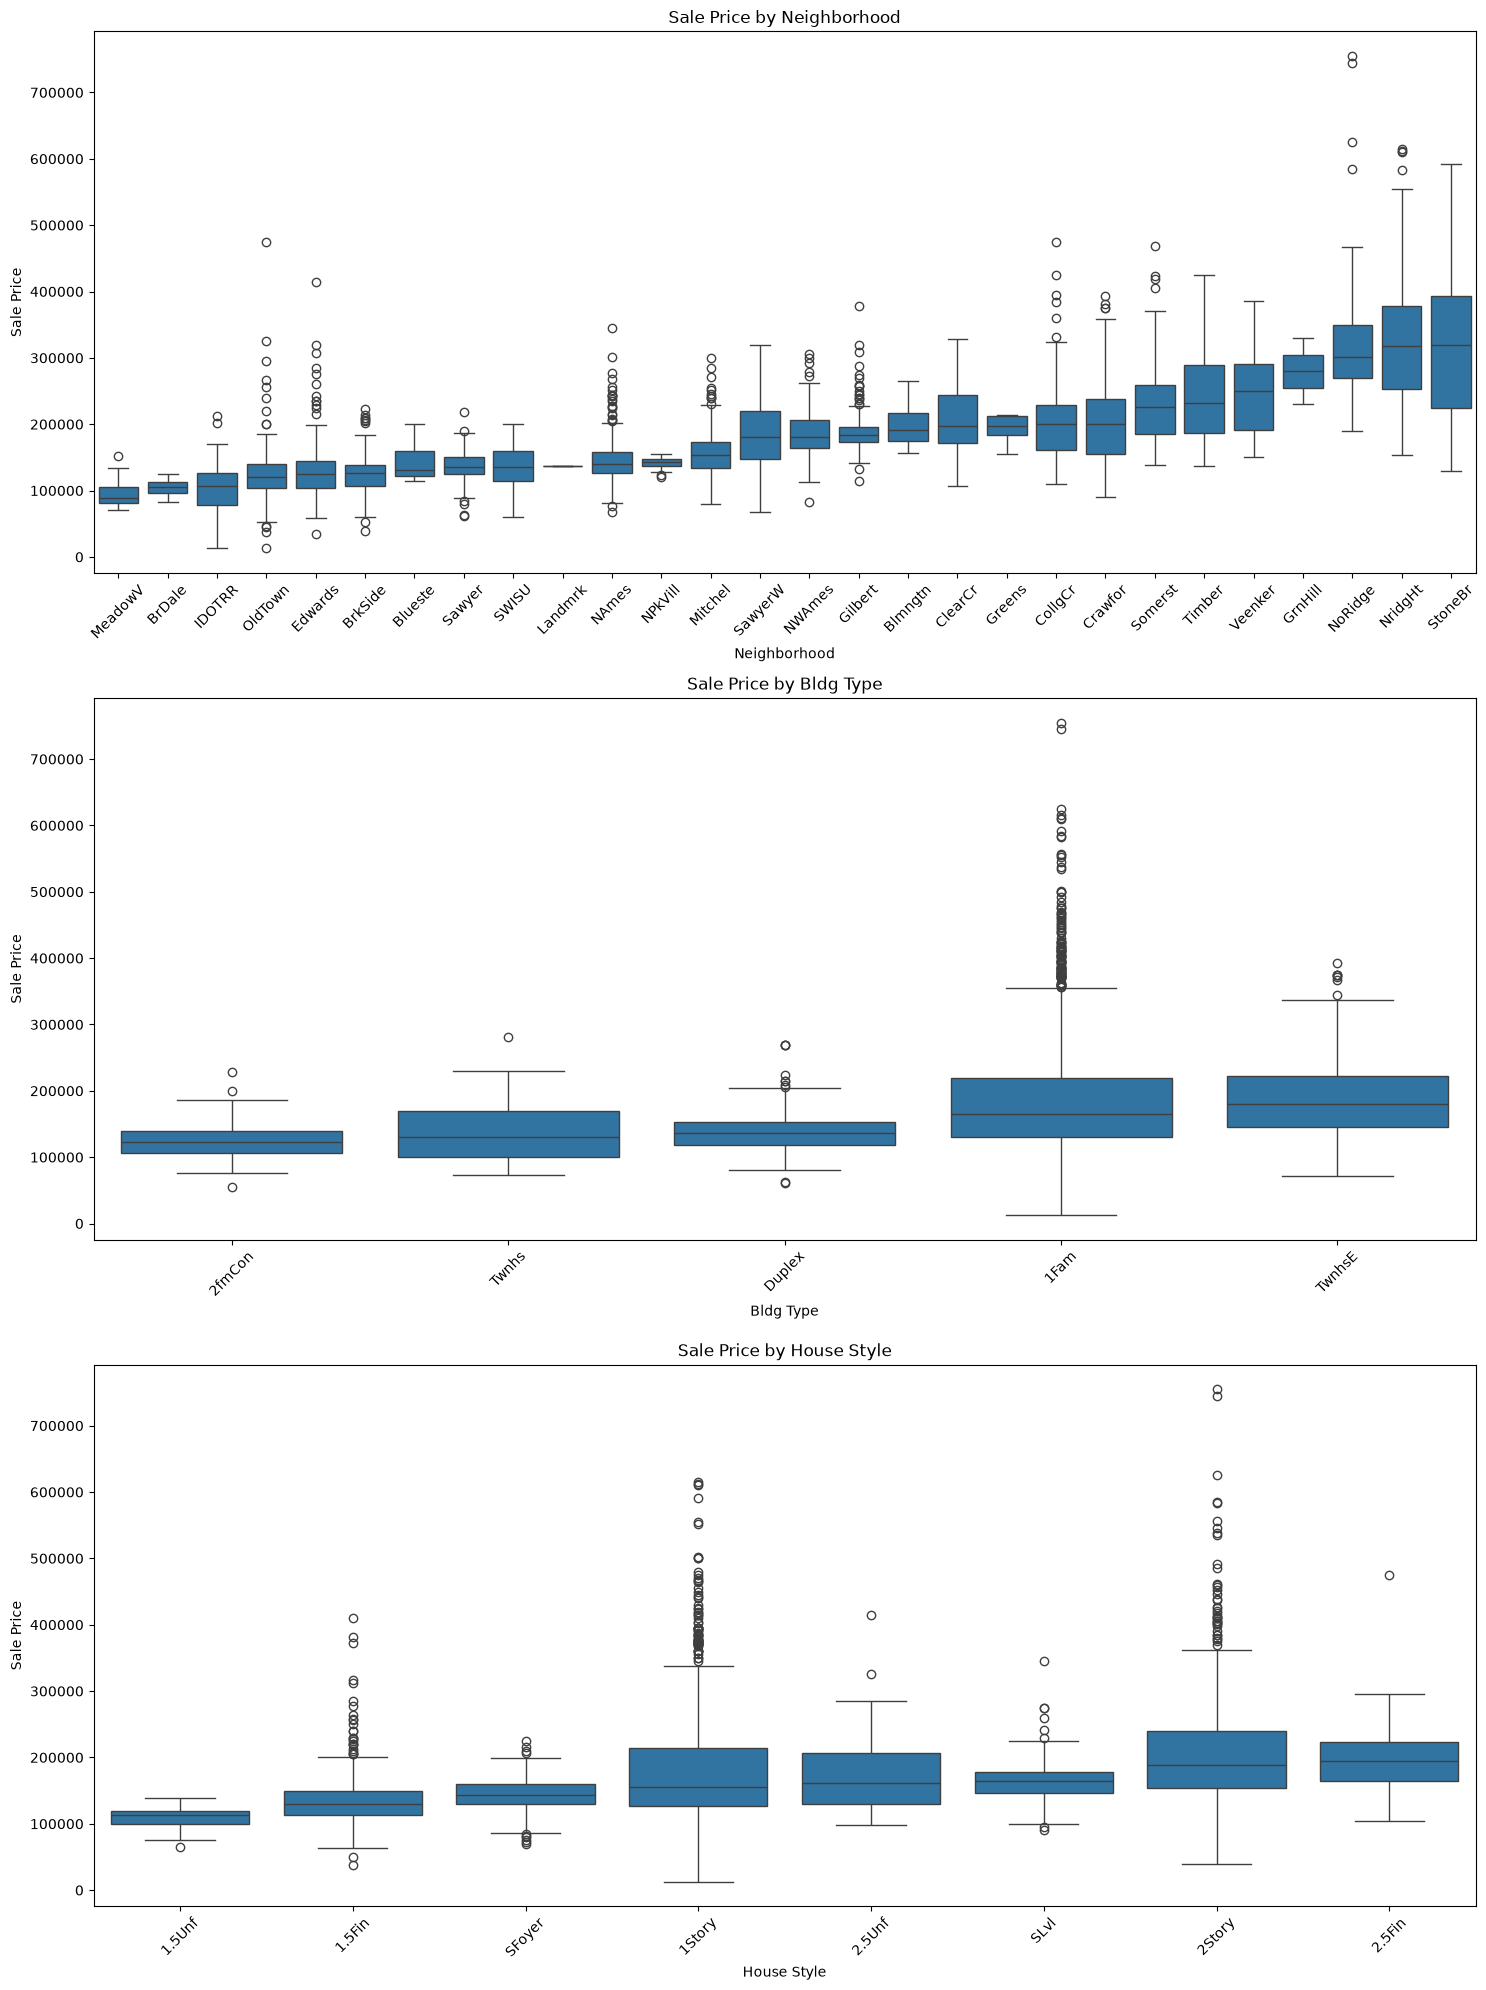

In [ ]:
# Explore sale prices across categories
price_comparison_features = [
    "Neighborhood",
    "Bldg Type",
    "House Style"
]

fig, axes = plt.subplots(3, 1, figsize=(15, 20))

for feature, ax in zip(price_comparison_features, axes):
    category_order = (
        df.groupby(feature, observed=True)["SalePrice"]
        .median()
        .sort_values()
        .index
    )

    sns.boxplot(
        data=df,
        x=feature,
        y="SalePrice",
        order=category_order,
        ax=ax
    )

    ax.set_title(f"Sale Price by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Sale Price")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [46]:
# Summarize price differences by category
for feature in price_comparison_features:
    print(f"\nMedian sale price and sample size by {feature}:")

    summary = (
        df.groupby(feature, observed=True)["SalePrice"]
        .agg(
            property_count="count",
            median_price="median",
            mean_price="mean"
        )
        .sort_values("median_price", ascending=False)
    )

    display(summary.round(2))


Median sale price and sample size by Neighborhood:


,property_count,median_price,mean_price
Neighborhood,,,
StoneBr,51,319000.0,324229.20
NridgHt,166,317750.0,322018.27
NoRidge,71,302000.0,330319.13
GrnHill,2,280000.0,280000.00
Veenker,24,250250.0,248314.58
Timber,72,232106.5,246599.54
Somerst,182,225500.0,229707.32
Crawfor,103,200624.0,207550.83
CollgCr,267,200000.0,201803.43



Median sale price and sample size by Bldg Type:


,property_count,median_price,mean_price
Bldg Type,,,
TwnhsE,233,180000.0,192311.91
1Fam,2425,165000.0,184812.04
Duplex,109,136905.0,139808.94
Twnhs,101,130000.0,135934.06
2fmCon,62,122250.0,125581.71



Median sale price and sample size by House Style:


,property_count,median_price,mean_price
House Style,,,
2.5Fin,8,194000.0,220000.00
2Story,873,189000.0,206990.16
SLvl,128,165000.0,165527.38
2.5Unf,24,160950.0,177158.33
1Story,1481,155000.0,178699.88
SFoyer,83,143000.0,143472.66
1.5Fin,314,129675.0,137529.92
1.5Unf,19,113000.0,109663.16


### 4.3 Categorical Feature Analysis

The categorical features show substantial variation in category frequencies.

`Neighborhood` contains 28 categories, ranging from 443 properties in `NAmes` to a single property in `Landmrk`. `MS Zoning` is dominated by `RL` (2,273 properties), while `Bldg Type` is dominated by `1Fam` (2,425 properties). `1Story` is the most common house style, and `VinylSd` is the most common exterior material.

The distribution of `Sale Condition` is highly concentrated in `Normal`, which accounts for 2,413 properties. Several exterior and neighborhood categories have very small sample sizes.

Boxplots show substantial differences in sale-price distributions across neighborhoods, building types, and house styles. Neighborhood appears particularly informative, although the observed differences may reflect several interacting property characteristics rather than a single factor.

**Modeling implications:** Categorical variables will be retained for further analysis. One-hot encoding with support for previously unseen categories is a suitable baseline approach. Rare categories will not be removed automatically; their treatment will depend on the modeling strategy and validation results.

## 5. Experimental Setup and Data Splitting

Before training machine learning models, we need to establish a reliable experimental setup.

The dataset will be divided into:

- **Training set (80%):** Used for preprocessing, model training, cross-validation, and hyperparameter tuning.
- **Test set (20%):** Reserved for the final evaluation of the selected model.

All preprocessing operations, including missing-value imputation and categorical encoding, will be fitted using training data only.

The test set will remain untouched throughout model development to provide an unbiased estimate of the selected model's generalization performance.

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
# Define target
TARGET = "SalePrice"

# Columns excluded from predictors
DROP_COLUMNS = [
    "Order",
    "PID",
    "LogSalePrice"
]

# Create X and y
X = df.drop(columns=[TARGET] + DROP_COLUMNS)
y = df[TARGET]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget variable:")
display(y.head())

print("\nFeature sample:")
display(X.head())

Features shape: (2930, 79)
Target shape: (2930,)

Target variable:


0    215000
1    105000
2    172000
3    244000
4    189900
Name: SalePrice, dtype: int64


Feature sample:


,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
3,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
4,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal


In [49]:
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2344, 79)
Testing features: (586, 79)
Training target: (2344,)
Testing target: (586,)


In [50]:
target_comparison = pd.DataFrame({
    "Training": y_train.describe(),
    "Testing": y_test.describe()
})

display(target_comparison.round(2))

,Training,Testing
count,2344.00,586.00
mean,178582.21,189651.47
std,77125.07,89617.26
min,12789.00,44000.00
25%,129000.00,130000.00
50%,160000.00,165000.00
75%,210000.00,228375.00
max,755000.00,625000.00


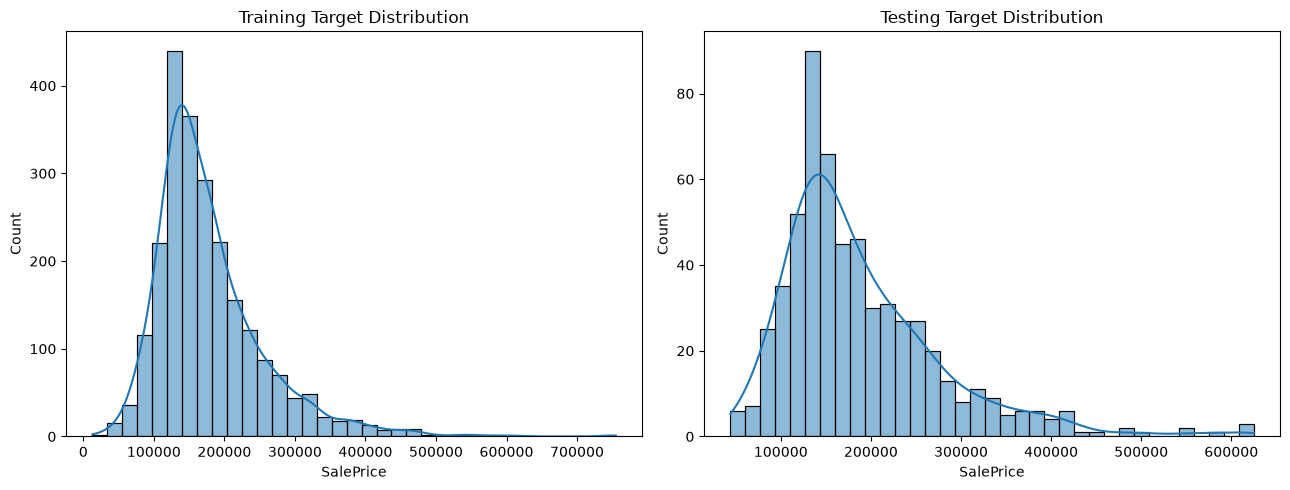

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(y_train, bins=35, kde=True, ax=axes[0])
axes[0].set_title("Training Target Distribution")

sns.histplot(y_test, bins=35, kde=True, ax=axes[1])
axes[1].set_title("Testing Target Distribution")

plt.tight_layout()
plt.show()

**They are not identical but they are comparable and that's what we need.**

In [52]:
print("Training missing values:", X_train.isna().sum().sum())
print("Testing missing values:", X_test.isna().sum().sum())

print("Training target missing:", y_train.isna().sum())
print("Testing target missing:", y_test.isna().sum())

Training missing values: 12544
Testing missing values: 3205
Training target missing: 0
Testing target missing: 0


## 6. Data Preprocessing

Build a reusable preprocessing pipeline that handles missing values and categorical encoding.

All preprocessing transformations will be learned from training data only, preventing information leakage from validation or test data.

The initial preprocessing strategy will use:

- Median imputation for numerical features.
- Most-frequent-value imputation for categorical features.
- One-hot encoding for categorical features.
- Passthrough of numerical features after imputation.

This will provide a consistent preprocessing baseline for comparing different regression models.

In [54]:
# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# "MS SubClass" is a categorical variable encoded numerically
numeric_features.remove("MS SubClass")
categorical_features.append("MS SubClass")

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 35
Number of categorical features: 44

Numerical features:
['Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold']

Categorical features:
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 

In [69]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler 

In [56]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

In [57]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [58]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

In [59]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (2344, 330)
Testing data shape: (586, 330)


In [60]:
from scipy import sparse

if sparse.issparse(X_train_processed):
    train_missing = np.isnan(X_train_processed.data).sum()
    test_missing = np.isnan(X_test_processed.data).sum()
else:
    train_missing = np.isnan(X_train_processed).sum()
    test_missing = np.isnan(X_test_processed).sum()

print("Missing values in processed training data:", train_missing)
print("Missing values in processed testing data:", test_missing)

Missing values in processed training data: 0
Missing values in processed testing data: 0


In [61]:
feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))

print("\nFirst 30 transformed features:")
print(feature_names[:30])

Number of transformed features: 330

First 30 transformed features:
['num__Lot Frontage' 'num__Lot Area' 'num__Overall Qual'
 'num__Overall Cond' 'num__Year Built' 'num__Year Remod/Add'
 'num__Mas Vnr Area' 'num__BsmtFin SF 1' 'num__BsmtFin SF 2'
 'num__Bsmt Unf SF' 'num__Total Bsmt SF' 'num__1st Flr SF'
 'num__2nd Flr SF' 'num__Low Qual Fin SF' 'num__Gr Liv Area'
 'num__Bsmt Full Bath' 'num__Bsmt Half Bath' 'num__Full Bath'
 'num__Half Bath' 'num__Bedroom AbvGr' 'num__Kitchen AbvGr'
 'num__TotRms AbvGrd' 'num__Fireplaces' 'num__Garage Yr Blt'
 'num__Garage Cars' 'num__Garage Area' 'num__Wood Deck SF'
 'num__Open Porch SF' 'num__Enclosed Porch' 'num__3Ssn Porch']


## 7. Baseline Regression Models

Establish baseline predictive performance using several regression algorithms.

Compare:

- Dummy Regression as a reference benchmark.
- Linear Regression as a basic linear model.
- Ridge Regression to evaluate the effect of L2 regularization.
- Random Forest Regression to capture nonlinear relationships and feature interactions.
- Gradient Boosting Regressor: builds trees sequentially to improve predictions by correcting previous model errors.

All models will use the same preprocessing strategy and five-fold cross-validation on the training dataset.

The held-out test set will remain untouched until final model selection.

In [62]:
from sklearn.dummy import DummyRegressor 
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.model_selection import KFold, cross_validate

In [63]:
# Define the models 
models = {
    "Dummy": DummyRegressor(
        strategy="mean"
    ),

    "Linear Regression": LinearRegression(),

    "Ridge": Ridge(
        alpha=1.0
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

In [64]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [65]:
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}

In [66]:
results = []

for model_name, model in models.items():

    # Combine preprocessing and model into one pipeline
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    results.append({
        "Model": model_name,
        "RMSE": -scores["test_rmse"].mean(),
        "RMSE Std": scores["test_rmse"].std(),
        "MAE": -scores["test_mae"].mean(),
        "MAE Std": scores["test_mae"].std(),
        "R2": scores["test_r2"].mean(),
        "R2 Std": scores["test_r2"].std()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(3))

,Model,RMSE,RMSE Std,MAE,MAE Std,R2,R2 Std
0,Gradient Boosting,26222.295,7427.913,16019.924,1523.775,0.875,0.076
1,Random Forest,26570.443,5862.297,16053.088,1501.851,0.875,0.055
2,Linear Regression,30664.240,8846.887,17408.766,814.443,0.829,0.107
3,Ridge,33152.936,9517.417,19420.144,1262.191,0.800,0.124
4,Dummy,77086.274,2662.807,56121.710,1965.295,-0.002,0.001


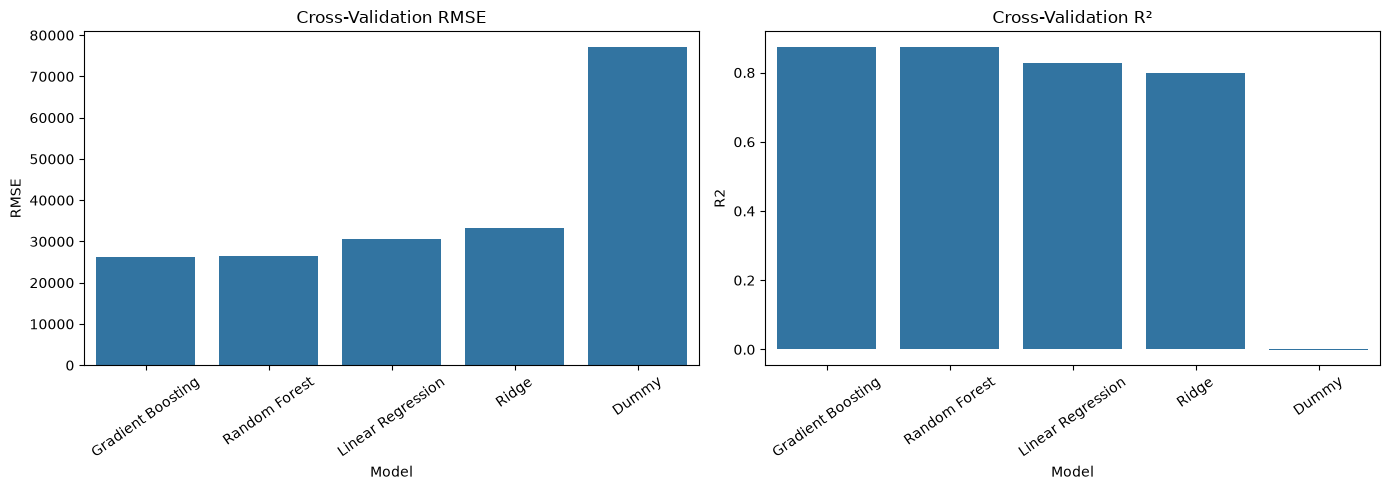

In [67]:
# Visualize Models' Performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    ax=axes[0]
)

axes[0].set_title("Cross-Validation RMSE")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(
    data=results_df,
    x="Model",
    y="R2",
    ax=axes[1]
)

axes[1].set_title("Cross-Validation R²")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

### 7.1 Baseline Model Evaluation

Gradient Boosting achieved the lowest average RMSE (26,222), closely followed by Random Forest (26,570). Both models achieved an average R² of approximately 0.875 and MAE values around 16,000.

Linear Regression achieved an RMSE of approximately 30,664 and R² of 0.829, indicating that the ensemble methods captured additional predictive patterns beyond the initial linear baseline.

Ridge Regression performed worse than ordinary Linear Regression under its initial configuration. Since numerical features were not standardized, the effect of regularization requires further investigation before drawing conclusions.

The Dummy Regressor achieved an RMSE of approximately 77,086 and an R² close to zero, providing a useful reference benchmark.

**Preliminary conclusion:** Gradient Boosting and Random Forest are the strongest initial candidates. Further experimentation is required before selecting a final model.

In [70]:
numeric_pipeline_scaled = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [71]:
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline_scaled, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

In [72]:
scaled_models = {
    "Linear Regression (Scaled)": LinearRegression(),

    "Ridge (Scaled)": Ridge(alpha=1.0)
}

In [73]:
scaled_results = []

for model_name, model in scaled_models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor_scaled),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    scaled_results.append({
        "Model": model_name,
        "RMSE": -scores["test_rmse"].mean(),
        "RMSE Std": scores["test_rmse"].std(),
        "MAE": -scores["test_mae"].mean(),
        "R2": scores["test_r2"].mean()
    })

scaled_results_df = pd.DataFrame(scaled_results)

display(scaled_results_df.round(3))

,Model,RMSE,RMSE Std,MAE,R2
0,Linear Regression (Scaled),28417.683,9080.398,16549.856,0.851
1,Ridge (Scaled),29419.823,9139.027,16651.233,0.840


In [74]:
original_linear_ridge = results_df[
    results_df["Model"].isin(["Linear Regression", "Ridge"])
][["Model", "RMSE", "MAE", "R2"]].copy()

original_linear_ridge["Experiment"] = "Unscaled"

scaled_comparison = scaled_results_df[
    ["Model", "RMSE", "MAE", "R2"]
].copy()

scaled_comparison["Model"] = (
    scaled_comparison["Model"]
    .str.replace(" (Scaled)", "", regex=False)
)

scaled_comparison["Experiment"] = "Scaled"

linear_ridge_comparison = pd.concat(
    [original_linear_ridge, scaled_comparison],
    ignore_index=True
)

display(
    linear_ridge_comparison.sort_values(
        ["Model", "Experiment"]
    ).round(3)
)

,Model,RMSE,MAE,R2,Experiment
2,Linear Regression,28417.683,16549.856,0.851,Scaled
0,Linear Regression,30664.240,17408.766,0.829,Unscaled
3,Ridge,29419.823,16651.233,0.840,Scaled
1,Ridge,33152.936,19420.144,0.800,Unscaled


In [75]:
ensemble_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

In [76]:
fold_results = []

for model_name, model in ensemble_models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    for fold_idx in range(5):

        fold_results.append({
            "Model": model_name,
            "Fold": fold_idx + 1,
            "RMSE": -scores["test_rmse"][fold_idx],
            "MAE": -scores["test_mae"][fold_idx],
            "R2": scores["test_r2"][fold_idx]
        })

fold_results_df = pd.DataFrame(fold_results)

display(
    fold_results_df.pivot(
        index="Fold",
        columns="Model",
        values="RMSE"
    ).round(2)
)

Model,Gradient Boosting,Random Forest
Fold,,
1,20146.18,20286.24
2,25759.11,29324.29
3,23952.90,26152.87
4,20757.77,20902.74
5,40495.51,36186.08


In [77]:
for metric in ["RMSE", "MAE", "R2"]:

    print(f"\n{metric} by fold:")

    display(
        fold_results_df.pivot(
            index="Fold",
            columns="Model",
            values=metric
        ).round(3)
    )


RMSE by fold:


Model,Gradient Boosting,Random Forest
Fold,,
1,20146.181,20286.240
2,25759.110,29324.289
3,23952.902,26152.867
4,20757.774,20902.738
5,40495.509,36186.081



MAE by fold:


Model,Gradient Boosting,Random Forest
Fold,,
1,14665.624,14474.807
2,16165.927,16505.506
3,15882.205,16195.317
4,14591.842,14535.162
5,18794.023,18554.647



R2 by fold:


Model,Gradient Boosting,Random Forest
Fold,,
1,0.925,0.924
2,0.881,0.846
3,0.913,0.897
4,0.928,0.927
5,0.728,0.783


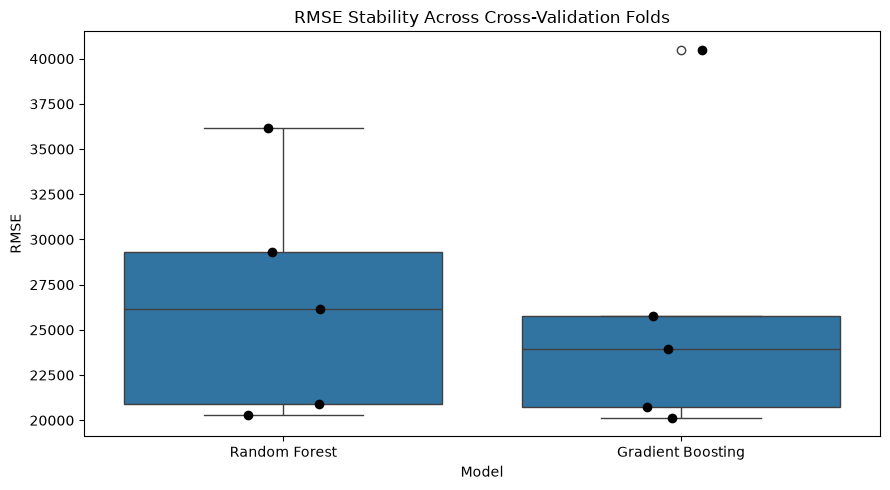

In [79]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=fold_results_df,
    x="Model",
    y="RMSE"
)

sns.stripplot(
    data=fold_results_df,
    x="Model",
    y="RMSE",
    color="black",
    size=7
)

plt.title("RMSE Stability Across Cross-Validation Folds")
plt.ylabel("RMSE")
plt.xlabel("Model")

plt.tight_layout()
plt.show()

**Fold 5 Needs more investigation** 

In [80]:
# Recreate the exact cross-validation splits
fold_splits = list(cv.split(X_train, y_train))

# Retrieve the fifth validation fold
train_idx_5, valid_idx_5 = fold_splits[4]

X_fold5 = X_train.iloc[valid_idx_5].copy()
y_fold5 = y_train.iloc[valid_idx_5].copy()

print("Fold 5 validation shape:", X_fold5.shape)

display(y_fold5.describe())

Fold 5 validation shape: (468, 79)


count       468.000000
mean     181619.679487
std       77721.725042
min       12789.000000
25%      133500.000000
50%      164995.000000
75%      213125.000000
max      615000.000000
Name: SalePrice, dtype: float64

In [81]:
fold_target_stats = []

for fold_number, (_, valid_idx) in enumerate(fold_splits, start=1):

    y_fold = y_train.iloc[valid_idx]

    fold_target_stats.append({
        "Fold": fold_number,
        "Count": len(y_fold),
        "Mean": y_fold.mean(),
        "Median": y_fold.median(),
        "Std": y_fold.std(),
        "Min": y_fold.min(),
        "Max": y_fold.max(),
        "90th Percentile": y_fold.quantile(0.90),
        "99th Percentile": y_fold.quantile(0.99)
    })

fold_target_stats_df = pd.DataFrame(fold_target_stats)

display(fold_target_stats_df.round(2))

,Fold,Count,Mean,Median,Std,Min,Max,90th Percentile,99th Percentile
0,1,469,176172.06,157000.0,73834.39,35311,500000,271000.0,428889.28
1,2,469,175057.11,159500.0,74791.24,34900,755000,261363.2,434800.00
2,3,469,180472.36,159000.0,81504.23,40000,745000,280000.0,471600.00
3,4,469,179596.30,161000.0,77662.46,39300,584500,279500.0,423960.00
4,5,468,181619.68,164995.0,77721.73,12789,615000,283250.0,452956.50


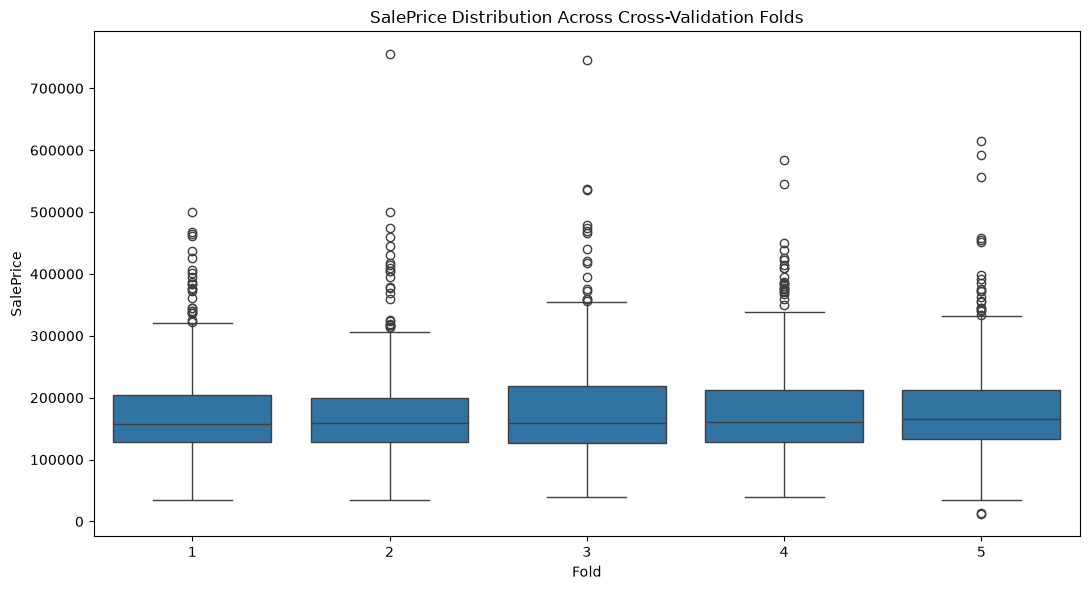

In [82]:
fold_target_plot = pd.DataFrame({
    "SalePrice": y_train.iloc[
        np.concatenate([idx for _, idx in fold_splits])
    ].values,
    "Fold": np.concatenate([
        np.repeat(i + 1, len(idx))
        for i, (_, idx) in enumerate(fold_splits)
    ])
})

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=fold_target_plot,
    x="Fold",
    y="SalePrice"
)

plt.title("SalePrice Distribution Across Cross-Validation Folds")
plt.tight_layout()
plt.show()

In [90]:
lowest_price_properties = df.nsmallest(10, "SalePrice")[
    [
        "Order",
        "PID",
        "SalePrice",
        "Sale Condition",
        "Sale Type",
        "Overall Qual",
        "Overall Cond",
        "Gr Liv Area",
        "Total Bsmt SF",
        "Garage Area",
        "Neighborhood",
        "Year Built",
        "Yr Sold"
    ]
]

display(lowest_price_properties)

,Order,PID,SalePrice,Sale Condition,Sale Type,Overall Qual,Overall Cond,Gr Liv Area,Total Bsmt SF,Garage Area,Neighborhood,Year Built,Yr Sold
181,182,902207130,12789,Abnorml,WD,2,2,832,678.0,780.0,OldTown,1923,2010
1553,1554,910251050,13100,Abnorml,WD,1,5,733,0.0,487.0,IDOTRR,1952,2008
726,727,902477120,34900,Abnorml,WD,4,5,720,720.0,0.0,IDOTRR,1920,2009
2843,2844,909101330,35000,Normal,ConLD,2,3,498,498.0,216.0,Edwards,1922,2006
2880,2881,911175430,35311,Abnorml,WD,2,3,480,480.0,308.0,IDOTRR,1949,2006
709,710,902205030,37900,Abnorml,WD,3,6,968,600.0,0.0,OldTown,1910,2009
1901,1902,534450090,39300,Normal,WD,1,3,334,0.0,0.0,BrkSide,1946,2007
1555,1556,911102170,40000,Normal,WD,4,4,1317,649.0,250.0,IDOTRR,1920,2008
727,728,902477130,44000,Abnorml,WD,3,3,797,245.0,0.0,IDOTRR,1900,2009
708,709,902205010,45000,Normal,WD,2,4,612,0.0,308.0,OldTown,1940,2009


In [87]:
fold5_predictions = {}

for model_name, model in ensemble_models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(
        X_train.iloc[train_idx_5],
        y_train.iloc[train_idx_5]
    )

    predictions = pipeline.predict(X_fold5)

    fold5_predictions[model_name] = predictions

In [88]:
fold5_error_analysis = df.loc[
    X_fold5.index,
    [
        "SalePrice",
        "Sale Condition",
        "Sale Type",
        "Overall Qual",
        "Gr Liv Area",
        "Total Bsmt SF",
        "Neighborhood",
        "Year Built"
    ]
].copy()

fold5_error_analysis["GB_Prediction"] = (
    fold5_predictions["Gradient Boosting"]
)

fold5_error_analysis["RF_Prediction"] = (
    fold5_predictions["Random Forest"]
)

fold5_error_analysis["GB_Error"] = (
    fold5_error_analysis["SalePrice"]
    - fold5_error_analysis["GB_Prediction"]
)

fold5_error_analysis["RF_Error"] = (
    fold5_error_analysis["SalePrice"]
    - fold5_error_analysis["RF_Prediction"]
)

fold5_error_analysis["GB_Absolute_Error"] = (
    fold5_error_analysis["GB_Error"].abs()
)

fold5_error_analysis["RF_Absolute_Error"] = (
    fold5_error_analysis["RF_Error"].abs()
)

display(
    fold5_error_analysis
    .sort_values("GB_Absolute_Error", ascending=False)
    .head(15)
    .round(2)
)

,SalePrice,Sale Condition,Sale Type,Overall Qual,Gr Liv Area,Total Bsmt SF,Neighborhood,Year Built,GB_Prediction,RF_Prediction,GB_Error,RF_Error,GB_Absolute_Error,RF_Absolute_Error
2180,183850,Partial,New,10,5095,5095.0,Edwards,2008,669521.96,544430.79,-485671.96,-360580.79,485671.96,360580.79
1498,160000,Partial,New,10,5642,6110.0,Edwards,2008,627723.41,533434.93,-467723.41,-373434.93,467723.41,373434.93
1063,615000,Normal,WD,10,2470,2535.0,NridgHt,2003,459754.59,454081.15,155245.41,160918.85,155245.41,160918.85
1637,591587,Partial,New,9,2338,2660.0,StoneBr,2006,439063.13,412414.50,152523.87,179172.50,152523.87,179172.50
1640,392000,Partial,New,8,1419,1419.0,StoneBr,2007,242079.29,245209.18,149920.71,146790.82,149920.71,146790.82
2332,556581,Partial,New,9,2868,1992.0,StoneBr,2005,424323.14,434962.31,132257.86,121618.69,132257.86,121618.69
956,375000,Normal,WD,7,2036,2136.0,Timber,1965,265959.87,233283.17,109040.13,141716.83,109040.13,141716.83
1553,13100,Abnorml,WD,1,733,0.0,IDOTRR,1952,90987.46,71997.65,-77887.46,-58897.65,77887.46,58897.65
1318,122000,Normal,WD,8,2358,684.0,OldTown,1872,197016.64,223646.55,-75016.64,-101646.55,75016.64,101646.55
91,362500,Normal,WD,8,2349,1231.0,NoRidge,1993,289942.93,312873.19,72557.07,49626.81,72557.07,49626.81


In [93]:
suspected_outliers = df.loc[
    df.index.isin([1498, 2180])
]

suspected_outliers

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice,LogSalePrice
1498,1499,908154235,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644.0,Unf,0.0,466.0,6110.0,GasA,Ex,Y,SBrkr,4692,950,0,5642,2.0,0.0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,2008.0,Fin,2.0,1418.0,TA,TA,Y,214,292,0,0,0,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000,11.982935
2180,2181,908154195,20,RL,128.0,39290,Pave,NaN,IR1,Bnk,AllPub,Inside,Gtl,Edwards,Norm,Norm,1Fam,1Story,10,5,2008,2009,Hip,CompShg,CemntBd,CmentBd,Stone,1224.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,4010.0,Unf,0.0,1085.0,5095.0,GasA,Ex,Y,SBrkr,5095,0,0,5095,1.0,1.0,2,1,2,1,Ex,15,Typ,2,Gd,Attchd,2008.0,Fin,3.0,1154.0,TA,TA,Y,546,484,0,0,0,0,NaN,NaN,Elev,17000,10,2007,New,Partial,183850,12.121881


- Overall Qual = 10 — the highest quality rating.
- Very large living areas: 5,642 and 5,095 sq ft.
- Excellent exterior and basement quality ratings.
- Sale Type = New.
- Sale Condition = Partial.

STILL I can't call them data errors

In [98]:
# CREATE alternative data excluding the suspected two observations  

suspected_indices = [1498, 2180]

X_train_alter = X_train.drop(
    index=suspected_indices,
    errors="ignore"
)

y_train_alter = y_train.drop(
    index=suspected_indices,
    errors="ignore"
)

print("Original training shape:", X_train.shape)
print("Alternative training shape:", X_train_alter.shape)

print("Removed observations:", len(X_train) - len(X_train_alter))

Original training shape: (2344, 79)
Alternative training shape: (2342, 79)
Removed observations: 2


In [100]:
sensitivity_results = []

for model_name, model in ensemble_models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train_alter,
        y_train_alter,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    sensitivity_results.append({
        "Model": model_name,
        "RMSE": -scores["test_rmse"].mean(),
        "RMSE Std": scores["test_rmse"].std(),
        "MAE": -scores["test_mae"].mean(),
        "R2": scores["test_r2"].mean()
    })

sensitivity_results_df = pd.DataFrame(sensitivity_results)

display(sensitivity_results_df.round(3))

,Model,RMSE,RMSE Std,MAE,R2
0,Random Forest,24987.596,607.674,15701.053,0.894
1,Gradient Boosting,23193.013,1143.542,15366.140,0.908


In [101]:
# Compare the two experiments
original_results = results_df[
    results_df["Model"].isin(
        ["Gradient Boosting", "Random Forest"]
    )
][["Model", "RMSE", "RMSE Std", "MAE", "R2"]].copy()

original_results["Experiment"] = "Original"

sensitivity_comparison = sensitivity_results_df.copy()
sensitivity_comparison["Experiment"] = "Excluding 2 observations"

final_comparison = pd.concat(
    [original_results, sensitivity_comparison],
    ignore_index=True
)

display(
    final_comparison.sort_values(
        ["Model", "Experiment"]
    ).round(3)
)

,Model,RMSE,RMSE Std,MAE,R2,Experiment
3,Gradient Boosting,23193.013,1143.542,15366.140,0.908,Excluding 2 observations
0,Gradient Boosting,26222.295,7427.913,16019.924,0.875,Original
2,Random Forest,24987.596,607.674,15701.053,0.894,Excluding 2 observations
1,Random Forest,26570.443,5862.297,16053.088,0.875,Original


### 7.2 Outlier Sensitivity Analysis

During model diagnostics, two observations (Order 1498 and Order 2180) were identified as particularly influential.

Both properties had exceptionally large above-ground living areas exceeding 5,000 square feet, maximum overall quality ratings, and unusually low sale prices relative to their recorded characteristics. Both were also associated with new construction and partial sales.

Further inspection showed that their area measurements were internally consistent. Therefore, they were not automatically classified as data-entry errors.

To evaluate their influence on model performance, an outlier sensitivity analysis was conducted by comparing two training scenarios:

- Original dataset: all training observations retained.
- Alternative dataset: the two identified observations excluded from training.

Five-fold cross-validation produced the following results:

| Model | Original RMSE | Excluding two observations |
|---|---:|---:|
| Gradient Boosting | 26,222 | 23,193 |
| Random Forest | 26,570 | 24,988 |

Both models demonstrated improved cross-validation performance under the alternative scenario. Gradient Boosting achieved the largest improvement, with an RMSE reduction of approximately 11.55%.

However, the observations were excluded from the training dataset before regenerating cross-validation folds. Consequently, the comparison also reflects differences in fold composition and should be interpreted as a sensitivity analysis rather than definitive proof that the observations alone caused the performance improvement.

**Conclusion:** The two observations have a substantial influence on the modeling results and warrant explicit documentation. They will remain in the original dataset, while the alternative experiment will be retained for comparison. Gradient Boosting and Random Forest will both proceed to further optimization.

## 9. Hyperparameter Optimization

Hyperparameter optimization will be performed using the alternative training dataset.

Randomized Search with five-fold cross-validation will be used to explore promising hyperparameter configurations for Gradient Boosting and Random Forest.


In [102]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

In [103]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        random_state=42
    ))
])

In [104]:
rf_params = {
    "model__n_estimators": randint(200, 601),
    "model__max_depth": [None, 10, 15, 20, 25, 30],
    "model__min_samples_split": randint(2, 16),
    "model__min_samples_leaf": randint(1, 9),
    "model__max_features": [1.0, "sqrt", 0.7]
}

In [106]:
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_alter, y_train_alter)

print("Best parameters:")
print(rf_search.best_params_)

print("\nBest CV RMSE:")
print(-rf_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'model__max_depth': 20, 'model__max_features': 0.7, 'model__min_samples_leaf': 4, 'model__min_samples_split': 8, 'model__n_estimators': 463}

Best CV RMSE:
24962.667701251667


In [107]:
gb_params = {
    "model__n_estimators": randint(100, 501),
    "model__learning_rate": uniform(0.02, 0.18),
    "model__max_depth": randint(1, 5),
    "model__min_samples_split": randint(2, 16),
    "model__min_samples_leaf": randint(1, 9),
    "model__subsample": uniform(0.7, 0.3),
    "model__max_features": [None, "sqrt", 0.7]
}

In [108]:
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_params,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train_alter, y_train_alter)

print("Best parameters:")
print(gb_search.best_params_)

print("\nBest CV RMSE:")
print(-gb_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'model__learning_rate': np.float64(0.061560888611986816), 'model__max_depth': 4, 'model__max_features': 0.7, 'model__min_samples_leaf': 4, 'model__min_samples_split': 8, 'model__n_estimators': 363, 'model__subsample': np.float64(0.7103165563345655)}

Best CV RMSE:
20619.12327136985


In [109]:
tuning_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Best CV RMSE": -rf_search.best_score_,
        "Best Parameters": rf_search.best_params_
    },
    {
        "Model": "Gradient Boosting",
        "Best CV RMSE": -gb_search.best_score_,
        "Best Parameters": gb_search.best_params_
    }
])

display(tuning_results)

,Model,Best CV RMSE,Best Parameters
0,Random Forest,24962.667701,"{'model__max_depth': 20, 'model__max_features'..."
1,Gradient Boosting,20619.123271,"{'model__learning_rate': 0.061560888611986816,..."


## Section 10 — Final Model Evaluation

In [110]:
# Retrieve the best Gradient Boosting pipeline
best_model = gb_search.best_estimator_

# Fit using the alternative training dataset
best_model.fit(X_train_alter, y_train_alter)

print("Final model fitted successfully.")

Final model fitted successfully.


In [111]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict on the untouched test set
y_test_pred = best_model.predict(X_test)

# Calculate evaluation metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

final_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Test Score": [test_mae, test_rmse, test_r2]
})

display(final_metrics.round(3))

,Metric,Test Score
0,MAE,13969.872
1,RMSE,28864.293
2,R2,0.896


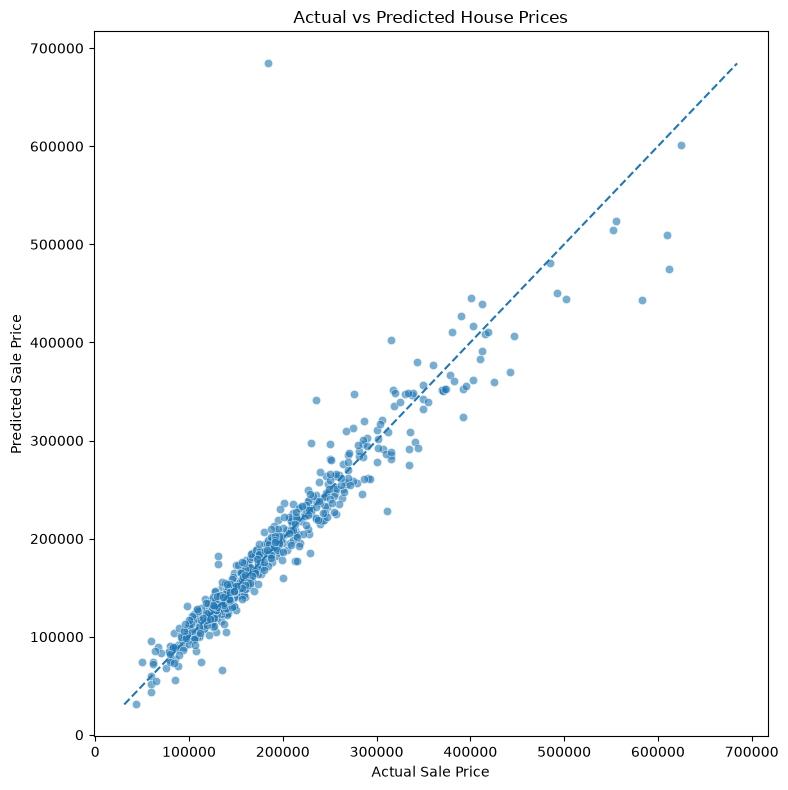

In [112]:
plt.figure(figsize=(8, 8))

sns.scatterplot(
    x=y_test,
    y=y_test_pred,
    alpha=0.6
)

min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")

plt.tight_layout()
plt.show()

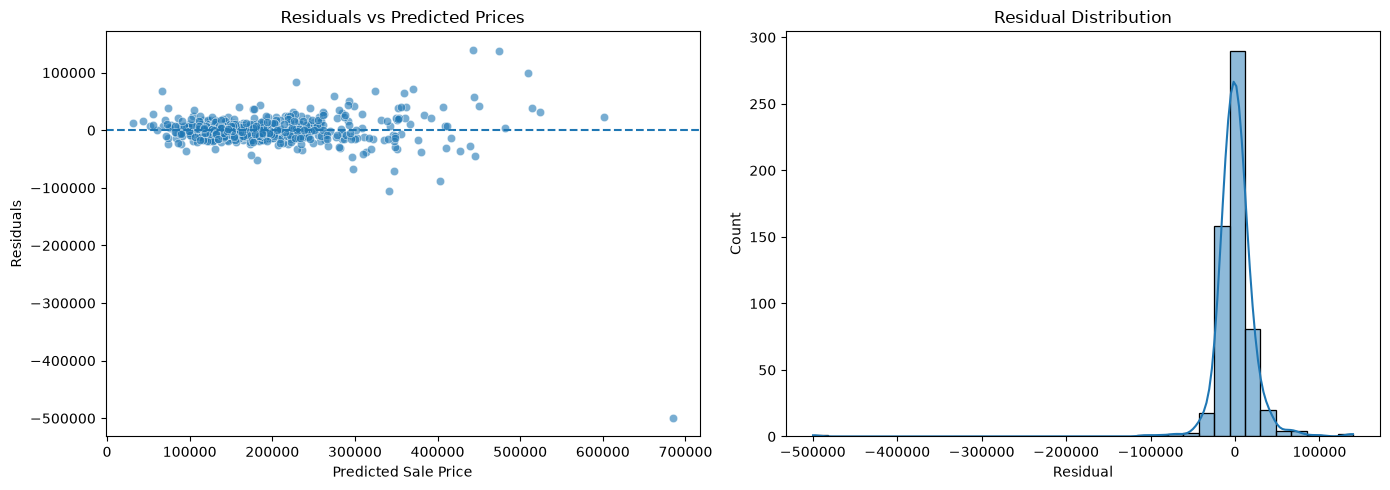

In [113]:
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    x=y_test_pred,
    y=residuals,
    alpha=0.6,
    ax=axes[0]
)

axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residuals vs Predicted Prices")
axes[0].set_xlabel("Predicted Sale Price")
axes[0].set_ylabel("Residuals")

sns.histplot(
    residuals,
    bins=35,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

In [114]:
test_predictions = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred
})

test_predictions["Residual"] = (
    test_predictions["Actual"] - test_predictions["Predicted"]
)

test_predictions["Absolute Error"] = (
    test_predictions["Residual"].abs()
)

display(
    test_predictions
    .sort_values("Absolute Error", ascending=False)
    .head(15)
    .round(2)
)

,Actual,Predicted,Residual,Absolute Error
2181,184750,684423.06,-499673.06,499673.06
433,582933,443200.93,139732.07,139732.07
44,611657,474724.61,136932.39,136932.39
2246,235000,340956.89,-105956.89,105956.89
432,610000,509956.99,100043.01,100043.01
2378,315000,402800.92,-87800.92,87800.92
1538,311500,228481.56,83018.44,83018.44
1641,441929,369879.51,72049.49,72049.49
2103,276000,347288.50,-71288.50,71288.50
1559,392500,323766.89,68733.11,68733.11


### Model Interpretation 

In [115]:
from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": permutation_results.importances_mean,
    "Importance Std": permutation_results.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

importance_df.head(20)

,Feature,Importance Mean,Importance Std
0,Overall Qual,20256.109724,1547.547434
1,Gr Liv Area,10090.235582,643.653134
2,Total Bsmt SF,1496.211798,359.121617
3,Year Built,1324.293399,604.121863
4,BsmtFin SF 1,1188.132175,241.938626
5,Overall Cond,918.734037,236.353753
6,Garage Cars,806.835601,667.676144
7,Year Remod/Add,576.923171,515.919955
8,Neighborhood,551.632555,79.026978
9,Lot Area,326.960489,360.856206


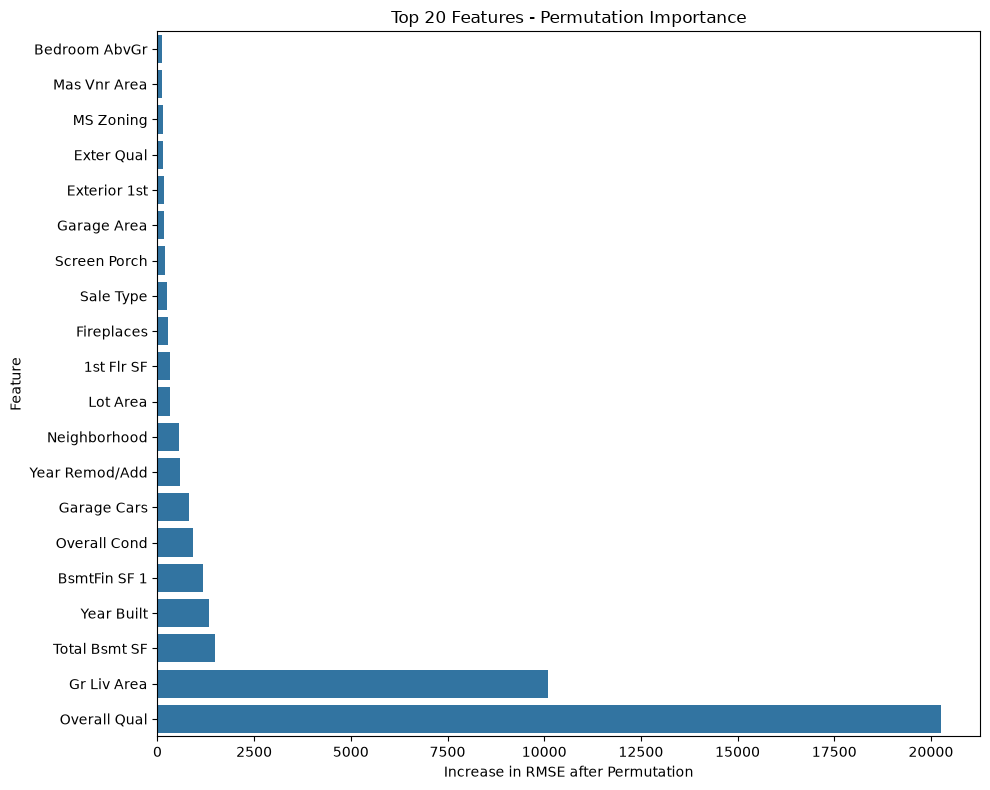

In [116]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = importance_df.head(20).sort_values(
    by="Importance Mean",
    ascending=True
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance Mean",
    y="Feature"
)

plt.title("Top 20 Features - Permutation Importance")
plt.xlabel("Increase in RMSE after Permutation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Final Conclusions

## 1. Project Objective

The objective of this project was to analyze the Ames Housing dataset and develop a regression model capable of predicting residential property sale prices based on their characteristics.

## 2. Data Exploration and Preparation

- Conducted exploratory data analysis to understand sale price distributions and relationships between property characteristics and prices.
- Investigated missing values, distinguishing structural missingness from other missing data.
- Examined numerical and categorical features to identify patterns and potential data quality issues.
- Identified two unusual training observations and evaluated their influence through a sensitivity analysis. They were excluded from the subsequent modeling experiment, while the original dataset was preserved.
- Developed a preprocessing pipeline using numerical imputation, categorical imputation, and one-hot encoding.

## 3. Modeling and Evaluation

- Established baseline models using Linear Regression, Ridge Regression, Random Forest, and Gradient Boosting, alongside a Dummy Regressor.
- Compared models using five-fold cross-validation.
- Investigated fold-level performance and prediction errors.
- Applied RandomizedSearchCV to optimize Random Forest and Gradient Boosting.
- Selected Gradient Boosting based on its stronger cross-validation performance.

The final model achieved the following results on the untouched test set:

| Metric | Test Result |
|---|---:|
| MAE | $13,969.87 |
| RMSE | $28,864.29 |
| R² | 0.896 |

The model explains approximately 89.6% of the variation in test sale prices. However, the difference between cross-validation RMSE and test RMSE indicates that performance varies across data samples.

## 4. Model Interpretation

Permutation importance identified the following features as the most influential:

1. Overall Qual
2. Gr Liv Area
3. Total Bsmt SF
4. Year Built
5. BsmtFin SF 1

Overall Qual and Gr Liv Area had substantially greater importance than the remaining features, indicating that overall construction quality and above-ground living area were particularly influential in the model's predictions.

These results describe predictive importance, not causal relationships.

## 5. Limitations

- Prediction errors were larger for some expensive and unusual properties.
- Residual analysis indicated a wider spread of errors at higher predicted prices.
- A small number of observations had particularly large prediction errors.
- The difference between cross-validation and test performance suggests that the model's generalization performance is not uniform.

## 6. Future Improvements

Potential directions for further experimentation include:

- Evaluating other boosting algorithms, such as XGBoost, LightGBM, and CatBoost.
- Investigating target transformation and alternative feature engineering techniques.
- Exploring methods to improve predictions for unusual properties.
- Evaluating performance across different price ranges and property segments.

## Final Remarks

This project provided an end-to-end regression experimentation workflow, covering data exploration, preprocessing, baseline modeling, cross-validation, error analysis, hyperparameter optimization, final evaluation, and model interpretation.

The final Gradient Boosting model achieved an R² of 0.896 on the test set. Although the results are promising, the residual analysis highlights areas where prediction accuracy could be improved.

The completed experimentation provides a foundation for developing a modular, reproducible machine learning project.